# Phase F: Der Wächter

Schritte 18 bis 20 aus `LERNPLAN.md`.

## Setup

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
LERNPFAD = ROOT / "data" / "processed" / "lernpfad"
BILDER = ROOT / "docs" / "assets" / "lernpfad"

sys.path.insert(0, str(ROOT))

## Schritt 18: Ein Wächter, der jede Station mit sich selbst vergleicht

Der Wächter sagt jeden Tag den Rücklauf vorher und schaut, wie weit die Messung danebenliegt. Solange die Station tickt wie immer, liegt die Vorhersage so daneben wie sonst auch. Als Vorhersage das 7-Tage-Mittel aus Phase C, das das LSTM in Phase D kaum geschlagen hat. Erst die Tage aus Phase C laden:

In [3]:
X = np.load(LERNPFAD / "X_tage.npy")
info = pd.read_csv(LERNPFAD / "info_tage.csv", parse_dates=["tag"])

7-Tage-Mittel je Station, wie in Notebook D:

In [4]:
rl = pd.DataFrame(X[:, :, 0])
rl["zaehler"] = info["zaehler"]
rl["tag"] = info["tag"]

mittel7 = np.full((len(info), 24), np.nan)
for z, gruppe in rl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns=["zaehler"]).asfreq("D")
    w = g.rolling(7).mean().shift(1)
    mittel7[gruppe.index] = w.loc[gruppe["tag"]].values

Die Differenz ist Messung minus Vorhersage, gemittelt über die 24 Stunden. Positiv heißt: wärmer als erwartet.

In [5]:
info["differenz"] = (X[:, :, 0] - mittel7).mean(axis=1)
info["differenz"].describe()

count    21970.000000
mean         0.007510
std          3.769401
min        -46.036905
25%         -1.338095
50%         -0.002976
75%          1.335119
max         53.136905
Name: differenz, dtype: float64

Bei 68956372 ging das Ventil am 08.08.2023 kaputt: Davor flossen nachts etwa 25 l/h, ab dem 19.08. dauerhaft rund 340 l/h.

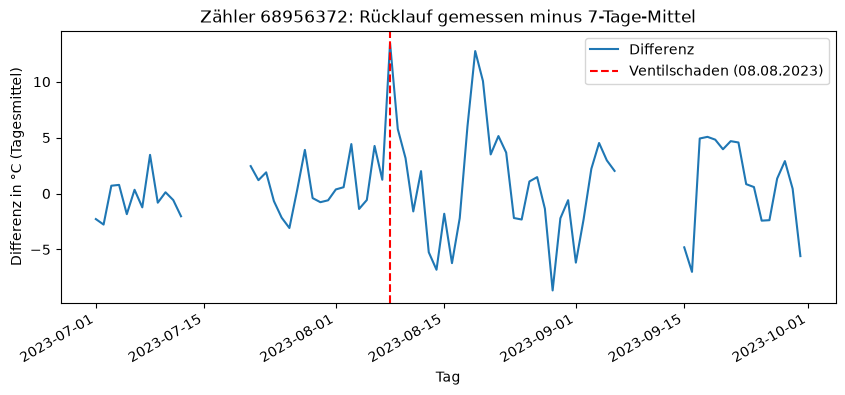

In [6]:
s = info[info["zaehler"] == 68956372].set_index("tag")
ax = s.loc["2023-07-01":"2023-09-30", "differenz"].plot(figsize=(10, 4))
ax.axvline(pd.Timestamp("2023-08-08"), color="red", linestyle="--")
ax.set_title("Zähler 68956372: Rücklauf gemessen minus 7-Tage-Mittel")
ax.set_xlabel("Tag")
ax.set_ylabel("Differenz in °C (Tagesmittel)")
ax.legend(["Differenz", "Ventilschaden (08.08.2023)"])

In [7]:
ax.figure.savefig(BILDER / "18_differenz_68956372.png", bbox_inches="tight")

Am Schadenstag +13 Grad, eine Woche später wieder 0. Dann besteht das 7-Tage-Mittel nur noch aus Tagen mit kaputtem Ventil, und der Wächter hat sich an den Schaden gewöhnt. Er muss in den ersten Tagen anschlagen oder gar nicht.

### Was ist unnormal?

Bei einer ruhigen Station sind 2 Grad Differenz normal, bei einer taktenden 8 Grad. Deshalb ein Fenster pro Station: Mittelwert und Streuung ihrer Differenzen in den letzten 8 Wochen. Die Differenz von heute, gemessen in diesen Streuungen, ist der z-Wert. `shift(1)`, damit der heutige Tag nicht in seinem eigenen Normalbereich steckt:

In [8]:
zwerte = np.full(len(info), np.nan)
for z, gruppe in info.groupby("zaehler"):
    d = gruppe.set_index("tag")["differenz"].asfreq("D")
    mittel = d.rolling(56, min_periods=28).mean().shift(1)
    streuung = d.rolling(56, min_periods=28).std().shift(1)
    zwerte[gruppe.index] = ((d - mittel) / streuung).loc[gruppe["tag"]].values
info["z"] = zwerte

Der Schadenstag:

In [9]:
info.loc[(info["zaehler"] == 68956372) & (info["tag"] == "2023-08-08"), "z"]

9533    5.872597
Name: z, dtype: float64

### Die Grenze

Zu hoch heißt kein Alarm, auch beim echten Schaden, zu niedrig heißt Alarm bei jeder Kleinigkeit. Fast alle Tage sind normal, die Alarme hier sind also fast alle Fehlalarme. Gezählt je Station und Jahr, beide Richtungen (`abs()`):

In [10]:
jahre = info["z"].notna().sum() / 365
for grenze in [2, 3, 4, 5, 6]:
    alarme = (info["z"].abs() >= grenze).sum()
    print("Grenze", grenze, "  Alarmtage:", alarme, "  je Station und Jahr:", round(alarme / jahre, 1))

Grenze 2   Alarmtage: 1329   je Station und Jahr: 23.8
Grenze 3   Alarmtage: 327   je Station und Jahr: 5.8
Grenze 4   Alarmtage: 118   je Station und Jahr: 2.1
Grenze 5   Alarmtage: 63   je Station und Jahr: 1.1
Grenze 6   Alarmtage: 37   je Station und Jahr: 0.7


Warnregel, festgelegt nur über die Fehlalarme: Alarm, wenn |z| ≥ 5. Das sind etwa 1 Alarm pro Station und Jahr. Ob damit echte Schäden gefunden werden, prüft erst Schritt 19.


Der Wächter bei 68956372 über die ganze Zeit (`s` neu bauen, weil die Spalte `z` dazugekommen ist):

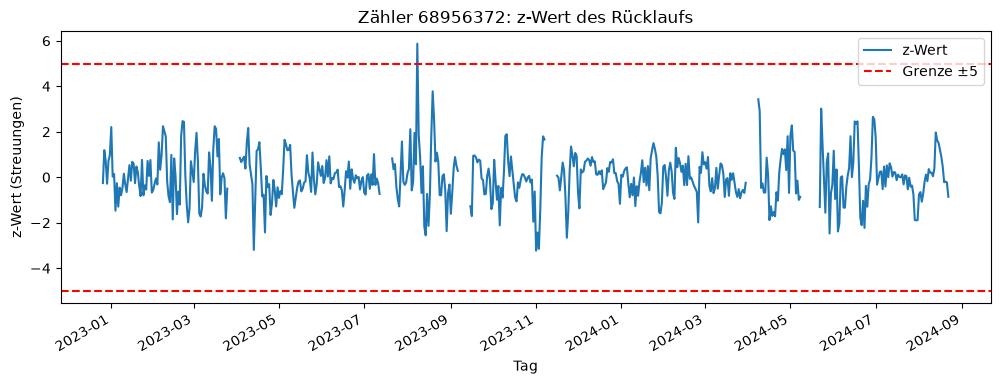

In [11]:
s = info[info["zaehler"] == 68956372].set_index("tag")
ax = s["z"].plot(figsize=(12, 4))
ax.axhline(5, color="red", linestyle="--")
ax.axhline(-5, color="red", linestyle="--")
ax.set_title("Zähler 68956372: z-Wert des Rücklaufs")
ax.set_xlabel("Tag")
ax.set_ylabel("z-Wert (Streuungen)")
ax.legend(["z-Wert", "Grenze ±5"])

In [12]:
ax.figure.savefig(BILDER / "18_z_68956372.png", bbox_inches="tight")

Genau ein Alarm in fast zwei Jahren, am Schadenstag. Insgesamt gibt es aber 63 Alarmtage bei 25 Stationen. In welchen Monaten?

In [13]:
alarme = info[info["z"].abs() >= 5]
alarme["tag"].dt.month.value_counts().sort_index()

tag
1      1
2      2
3      4
4      3
5     11
6      6
7      2
8      6
10    10
11     9
12     9
Name: count, dtype: int64

### Woher die Fehlalarme kommen

Gehäuft im Mai und von Oktober bis Dezember, beim Heizende und Heizbeginn. Wie stark schwankt die Differenz in jedem Monat?

In [14]:
info.groupby(info["tag"].dt.month)["differenz"].std().round(2)

tag
1     4.05
2     3.65
3     3.62
4     4.38
5     4.35
6     3.75
7     2.48
8     2.56
9     2.59
10    4.50
11    4.19
12    4.01
Name: differenz, dtype: float64

Im Sommer liegt die Vorhersage etwa ±2,5 Grad daneben, im Oktober ±4,5. Am 1. Oktober enthält das Fenster aber vor allem August und September und hält ±2,3 für normal. Ein gewöhnlicher Oktobertag, an dem die Heizung anspringt, ist dann über 4 Streuungen weg.

Idee: Heiztage nur mit Heiztagen und Sommertage nur mit Sommertagen vergleichen:

In [15]:
heizzeit = info["tag"].dt.month.isin([10, 11, 12, 1, 2, 3, 4])
zwerte_saison = np.full(len(info), np.nan)
for (z, h), gruppe in info.groupby(["zaehler", heizzeit]):
    d = gruppe.set_index("tag")["differenz"]
    mittel = d.rolling(56, min_periods=28).mean().shift(1)
    streuung = d.rolling(56, min_periods=28).std().shift(1)
    zwerte_saison[gruppe.index] = ((d - mittel) / streuung).values
info["z_saison"] = zwerte_saison

In [16]:
for spalte in ["z", "z_saison"]:
    j = info[spalte].notna().sum() / 365
    a = info[info[spalte].abs() >= 5]
    print(spalte, "  Alarme je Station und Jahr:", round(len(a) / j, 2))
    print(a["tag"].dt.month.value_counts().sort_index().to_dict())

z   Alarme je Station und Jahr: 1.13
{1: 1, 2: 2, 3: 4, 4: 3, 5: 11, 6: 6, 7: 2, 8: 6, 10: 10, 11: 9, 12: 9}
z_saison   Alarme je Station und Jahr: 1.08
{1: 1, 2: 2, 3: 4, 4: 3, 5: 13, 6: 5, 7: 2, 8: 6, 10: 3, 11: 8, 12: 9}


- Kaum ein Unterschied: 1,08 statt 1,13 Alarme pro Station und Jahr, im Oktober 3 statt 10, im Mai aber 13 statt 11.
- Der Rückgang im Oktober ist eine Falle: Stationen mit Daten erst ab September 2023 haben vorher keine Heiztage und bekommen anfangs gar keinen z-Wert. Der Wächter schaut dort weniger hin. Es bleibt beim einfachen Wächter.

## Schritt 19: Wie groß muss ein Schaden sein?

Weitere Schäden mit bekanntem Anfangsdatum gibt es nicht, die Begehung ist das Ende eines Schadens, nicht sein Anfang. Deshalb Schäden selbst einbauen, wie Prüfspray beim Rauchmelder: Ab einem Tag steigt der Messwert um einen festen Betrag. Am ersten Tag ist das Fenster noch unverändert, nur die Differenz von heute wird größer. Der z-Wert steigt also um Sprung / Streuung, und jeder Tag kann einmal Schadenstag sein.

Erst für den Rücklauf. Dafür die Streuung des Fensters für jeden Tag:

In [ ]:
fenster_streuung = np.full(len(info), np.nan)
for z, gruppe in info.groupby("zaehler"):
    d = gruppe.set_index("tag")["differenz"].asfreq("D")
    fenster_streuung[gruppe.index] = d.rolling(56, min_periods=28).std().shift(1).loc[gruppe["tag"]].values
info["streuung"] = fenster_streuung

In [ ]:
ok = info["z"].notna()
for sprung in [0, 2, 5, 10, 15, 20]:
    z_neu = info.loc[ok, "z"] + sprung / info.loc[ok, "streuung"]
    print(sprung, "Grad:  erkannt an", round((z_neu.abs() >= 5).mean() * 100), "% der Tage")

Ein Sprung von 10 Grad wird am ersten Tag nur zu 37 % erkannt, die Hälfte erst bei 12 bis 15 Grad. Bei einer unruhigen Station sind 10 Grad nur 2 Streuungen.

Beim Ventil ist der Durchfluss das deutlichere Signal: Bei 68956372 stieg der Rücklauf um ein Viertel, der Durchfluss nachts auf das 14-Fache. Derselbe Wächter für den Durchfluss (Kanal 1):

In [17]:
fl = pd.DataFrame(X[:, :, 1])
fl["zaehler"] = info["zaehler"]
fl["tag"] = info["tag"]

mittel7_fl = np.full((len(info), 24), np.nan)
for z, gruppe in fl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns=["zaehler"]).asfreq("D")
    w = g.rolling(7).mean().shift(1)
    mittel7_fl[gruppe.index] = w.loc[gruppe["tag"]].values

info["differenz_fl"] = (X[:, :, 1] - mittel7_fl).mean(axis=1)

z-Werte für den Durchfluss, die Streuung des Fensters gleich mit für das Prüfspray:

In [18]:
zwerte_fl = np.full(len(info), np.nan)
streuung_fl = np.full(len(info), np.nan)
for z, gruppe in info.groupby("zaehler"):
    d = gruppe.set_index("tag")["differenz_fl"].asfreq("D")
    mittel = d.rolling(56, min_periods=28).mean().shift(1)
    streuung = d.rolling(56, min_periods=28).std().shift(1)
    zwerte_fl[gruppe.index] = ((d - mittel) / streuung).loc[gruppe["tag"]].values
    streuung_fl[gruppe.index] = streuung.loc[gruppe["tag"]].values
info["z_fl"] = zwerte_fl
info["streuung_fl"] = streuung_fl

Passt die Grenze 5 auch hier ins Budget? Und der Schadenstag:

In [19]:
jahre_fl = info["z_fl"].notna().sum() / 365
print("Alarme je Station und Jahr:", round((info["z_fl"].abs() >= 5).sum() / jahre_fl, 2))
info.loc[(info["zaehler"] == 68956372) & (info["tag"] == "2023-08-08"), "z_fl"]

Alarme je Station und Jahr: 1.27


9533    12.822429
Name: z_fl, dtype: float64

1,27 Fehlalarme pro Station und Jahr, am Schadenstag z = 12,8 statt 5,9 beim Rücklauf. Jetzt das Prüfspray im Durchfluss:

In [20]:
ok_fl = info["z_fl"].notna()
for sprung in [0, 25, 50, 100, 150, 200]:
    z_neu = info.loc[ok_fl, "z_fl"] + sprung / info.loc[ok_fl, "streuung_fl"]
    print(sprung, "l/h:  erkannt an", round((z_neu.abs() >= 5).mean() * 100), "% der Tage")

0 l/h:  erkannt an 0 % der Tage
25 l/h:  erkannt an 4 % der Tage
50 l/h:  erkannt an 18 % der Tage
100 l/h:  erkannt an 48 % der Tage
150 l/h:  erkannt an 65 % der Tage
200 l/h:  erkannt an 75 % der Tage


Für die Abbildung mit Grenze 4 und 5:

In [21]:
kurve = []
for sprung in [0, 25, 50, 75, 100, 150, 200, 300]:
    z_neu = info.loc[ok_fl, "z_fl"] + sprung / info.loc[ok_fl, "streuung_fl"]
    kurve.append({"sprung": sprung, "grenze 4": (z_neu.abs() >= 4).mean() * 100, "grenze 5": (z_neu.abs() >= 5).mean() * 100})
kurve = pd.DataFrame(kurve).set_index("sprung")
kurve.round(0)

,grenze 4,grenze 5
sprung,,
0,1.0,0.0
25,8.0,4.0
50,27.0,18.0
75,46.0,35.0
100,58.0,48.0
150,73.0,65.0
200,82.0,75.0
300,91.0,87.0


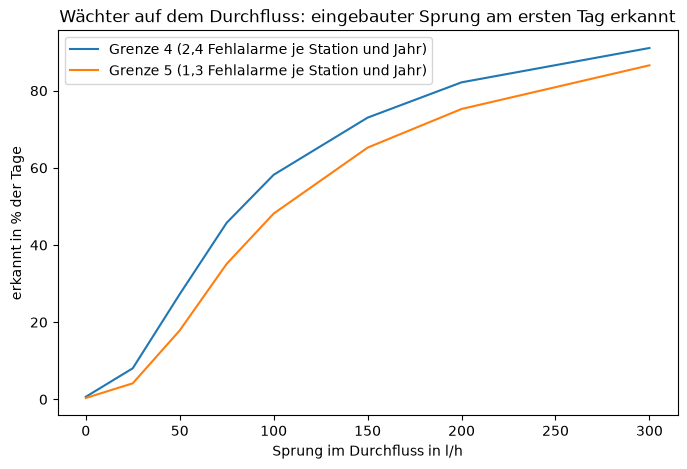

In [22]:
ax = kurve.plot(figsize=(8, 5))
ax.set_title("Wächter auf dem Durchfluss: eingebauter Sprung am ersten Tag erkannt")
ax.set_xlabel("Sprung im Durchfluss in l/h")
ax.set_ylabel("erkannt in % der Tage")
ax.legend(["Grenze 4 (2,4 Fehlalarme je Station und Jahr)", "Grenze 5 (1,3 Fehlalarme je Station und Jahr)"])

In [23]:
ax.figure.savefig(BILDER / "19_pruefspray_durchfluss.png", bbox_inches="tight")

Grenze 4 findet bei 150 l/h 73 statt 65 %, kostet aber fast doppelt so viele Fehlalarme (2,4 statt 1,3 pro Station und Jahr). Die Grenze bleibt bei 5, sie war vorher über das Budget festgelegt.

## Schritt 20: Der Wächter an den echten Begehungen

Dafür braucht es die Tage nach dem Stichtag, für alle 96 Zähler, auch die 40 nie begangenen. Das Tagesmittel reicht: Die Differenz zum 7-Tage-Mittel, gemittelt über den Tag, ist dasselbe wie Tagesmittel minus 7-Tage-Mittel der Tagesmittel.

In [25]:
METER_DIR = ROOT / "data" / "processed" / "real_meters"

zeilen = []
for datei in sorted(METER_DIR.glob("*.csv")):
    d = pd.read_csv(datei, parse_dates=["Timestamp"])
    d = d[d["Timestamp"] >= "2022-11-01"]
    d["tag"] = d["Timestamp"].dt.normalize()
    d["stunde"] = d["Timestamp"].dt.hour
    rl_tag = d.pivot(index="tag", columns="stunde", values="Return temperature (°C)")
    fl_tag = d.pivot(index="tag", columns="stunde", values="Volume flow (l/h)")
    voll = rl_tag.notna().all(axis=1) & fl_tag.notna().all(axis=1)
    zeilen.append(pd.DataFrame({"zaehler": int(datei.stem), "rl": rl_tag.mean(axis=1), "fl": fl_tag.mean(axis=1)})[voll])
tage = pd.concat(zeilen).reset_index()
tage.shape

(70632, 4)

Derselbe Wächter für Rücklauf und Durchfluss. Alarm, wenn einer der beiden |z| ≥ 5 hat:

In [26]:
for kanal in ["rl", "fl"]:
    zwerte = np.full(len(tage), np.nan)
    for z, gruppe in tage.groupby("zaehler"):
        s = gruppe.set_index("tag")[kanal].asfreq("D")
        differenz = s - s.rolling(7).mean().shift(1)
        mittel = differenz.rolling(56, min_periods=28).mean().shift(1)
        streuung = differenz.rolling(56, min_periods=28).std().shift(1)
        zwerte[gruppe.index] = ((differenz - mittel) / streuung).loc[gruppe["tag"]].values
    tage["z_" + kanal] = zwerte
tage["alarm"] = (tage["z_rl"].abs() >= 5) | (tage["z_fl"].abs() >= 5)      

Kontrolle, ob alles zu Schritt 18 und 19 passt:

In [27]:
tage.loc[(tage["zaehler"] == 68956372) & (tage["tag"] == "2023-08-08"), ["z_rl", "z_fl"]]

,z_rl,z_fl
24158,5.872597,12.822429


Die meisten Begehungen waren zum Heizbeginn, wo es sowieso viele Alarme gibt. Verglichen wird deshalb mit den 40 nie begangenen Zählern im selben Zeitfenster, wie mit einer Placebo-Gruppe. Fenster: 14 Tage nach der Begehung, gezählt nur mit mindestens 5 Tagen mit z-Wert:

In [28]:
labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv", parse_dates=["erste_begehung"])
nie_begangen = ~tage["zaehler"].isin(labels["zaehler"])
tage["hat_z"] = tage["z_rl"].notna() | tage["z_fl"].notna()

treffer = []
kontrolle = []
for _, b in labels.dropna(subset=["erste_begehung"]).iterrows():
    im_fenster = (tage["tag"] >= b["erste_begehung"]) & (tage["tag"] <= b["erste_begehung"] + pd.Timedelta(days=14)) & tage["hat_z"]
    station = tage[im_fenster & (tage["zaehler"] == b["zaehler"])]
    andere = tage[im_fenster & nie_begangen].groupby("zaehler").agg(tage=("tag", "size"), alarm=("alarm", "any"))
    andere = andere[andere["tage"] >= 5]
    if len(station) >= 5 and len(andere) >= 5:
        treffer.append(station["alarm"].any())
        kontrolle.append(andere["alarm"].mean())
print("Begehungen mit Alarm:", sum(treffer), "von", len(treffer))
print("Kontrollstationen mit Alarm im selben Zeitraum:", round(np.mean(kontrolle) * 100), "%")

Begehungen mit Alarm: 16 von 41
Kontrollstationen mit Alarm im selben Zeitraum: 20 %


Binomialtest: Wie wahrscheinlich sind so viele Treffer, wenn jede Begehung nur die Chance einer Kontrollstation hätte?

In [29]:
from scipy.stats import binomtest

binomtest(sum(treffer), len(treffer), np.mean(kontrolle), alternative="greater").pvalue

np.float64(0.0034344181526537315)

39 % gegen 20 %, p = 0,003. Zum Vergleich Notebook 32, ebenfalls 14 Tage: Normalverhaltensmodell 39 % gegen 19 % (p = 0,008), Prognose-LSTM 18 % gegen 20 % (kein Signal).

Der Ventiltausch an 68956351 am 09.09.2024:

In [30]:
tage.loc[(tage["zaehler"] == 68956351) & (tage["tag"] >= "2024-09-07") & (tage["tag"] <= "2024-09-12"), ["tag", "z_rl", "z_fl", "alarm"]]

,tag,z_rl,z_fl,alarm
12469,2024-09-07,0.152866,0.796860,False
12470,2024-09-08,-0.166196,1.779126,False
12471,2024-09-09,-2.876167,-15.264191,True
12472,2024-09-10,-9.413573,-19.165505,True
12473,2024-09-11,-4.453095,-5.477328,True
12474,2024-09-12,-3.269780,-3.164978,False


Alarm am Tag des Tauschs (Durchfluss z = −15). Beim Team kam er nach 2 Tagen (Normalverhaltensmodell) und nach 7 Tagen (LSTM).

### Ein Verdacht

Am Begehungstag arbeitet der Techniker an der Station. Kommen die Alarme vielleicht nur davon? An welchem Tag nach der Begehung kommt der erste Alarm, und was bleibt, wenn das Fenster erst 2 Tage danach beginnt?

In [ ]:
tage_bis_alarm = []
for _, b in labels.dropna(subset=["erste_begehung"]).iterrows():
    im_fenster = (tage["tag"] >= b["erste_begehung"]) & (tage["tag"] <= b["erste_begehung"] + pd.Timedelta(days=14)) & tage["hat_z"]
    station = tage[im_fenster & (tage["zaehler"] == b["zaehler"])]
    andere = tage[im_fenster & nie_begangen].groupby("zaehler").agg(tage=("tag", "size"), alarm=("alarm", "any"))
    andere = andere[andere["tage"] >= 5]
    if len(station) >= 5 and len(andere) >= 5 and station["alarm"].any():
        tage_bis_alarm.append((station.loc[station["alarm"], "tag"].min() - b["erste_begehung"]).days)
pd.Series(tage_bis_alarm).value_counts().sort_index()

In [ ]:
treffer = []
kontrolle = []
for _, b in labels.dropna(subset=["erste_begehung"]).iterrows():
    im_fenster = (tage["tag"] >= b["erste_begehung"] + pd.Timedelta(days=2)) & (tage["tag"] <= b["erste_begehung"] + pd.Timedelta(days=14)) & tage["hat_z"]
    station = tage[im_fenster & (tage["zaehler"] == b["zaehler"])]
    andere = tage[im_fenster & nie_begangen].groupby("zaehler").agg(tage=("tag", "size"), alarm=("alarm", "any"))
    andere = andere[andere["tage"] >= 5]
    if len(station) >= 5 and len(andere) >= 5:
        treffer.append(station["alarm"].any())
        kontrolle.append(andere["alarm"].mean())
print("Begehungen mit Alarm:", sum(treffer), "von", len(treffer), "  Kontrolle:", round(np.mean(kontrolle) * 100), "%")
binomtest(sum(treffer), len(treffer), np.mean(kontrolle), alternative="greater").pvalue

- 12 der 16 Treffer liegen am Begehungstag oder am Tag danach. Ab Tag 2 sind es 9 von 41 gegen 17 %, p = 0,28, also kein Unterschied mehr.
- Der Wächter bemerkt den Eingriff selbst, beim Ventil in 6 von 9 Fällen, aber nicht die kleine bleibende Veränderung danach. Laut Notebook 32 verschiebt eine Begehung den Betrieb im Mittel nur um etwa eine halbe Streuung. Das CUSUM im Normalverhaltensmodell zählt so eine Verschiebung Tag für Tag auf, eine Grenze von 5 Streuungen sieht sie nie. Die gleichen 39 % heißen also nicht, dass beide Wächter gleich gut sind.

## Ergebnis Phase F

- Der Wächter vergleicht jede Station mit sich selbst: 7-Tage-Mittel als Vorhersage, z-Wert aus einem Fenster von 8 Wochen, Alarm bei |z| ≥ 5. Die Grenze ist nur über die Fehlalarme festgelegt, etwa 1 pro Station und Jahr und Kanal.
- Am einzigen Schaden mit bekanntem Datum (68956372) schlägt er genau einmal an, am Schadenstag.
- Eingebaute Sprünge findet er erst ab einer gewissen Größe: 10 Grad im Rücklauf zu 37 %, 150 l/h im Durchfluss zu 65 %. Beim Ventil ist der Durchfluss der bessere Kanal.
- An den Begehungen bemerkt er den Eingriff selbst (39 % gegen 20 % in 14 Tagen), aber nicht die kleine Veränderung danach.
- **Grenzen:** Er gewöhnt sich an jeden Zustand, ein alter oder schleichender Schaden fällt nie auf (68956351: Ventil drei Jahre offen, bemerkt wurde nur der Tausch). Er sieht nur große, plötzliche Sprünge. Beim Heizbeginn und Heizende gibt es Fehlalarme. Und er sagt nur „anders“, nicht „was“, das muss die Diagnose aus Phase B und E klären.